In [26]:
import os
import json
import joblib
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub

warnings.filterwarnings('ignore')

# Load Dataset from KaggleHub
path = kagglehub.dataset_download("sufyankhot/goodreads-10k-dataset-integrated")
csv_file = [f for f in os.listdir(path) if f.endswith('.csv')][0]
df = pd.read_csv(os.path.join(path, csv_file))

print(f"Dataset Shape: {df.shape}")

Using Colab cache for faster access to the 'goodreads-10k-dataset-integrated' dataset.
Dataset Shape: (10000, 26)


In [27]:
df

,id,book_id,best_book_id,work_id,books_count,isbn,isbn13,authors,original_publication_year,original_title,...,ratings_1,ratings_2,ratings_3,ratings_4,ratings_5,image_url,small_image_url,tag_name,toread_count,currently_reading
0,1,2767052,2767052,2792775,272,439023483,9.780439e+12,Suzanne Collins,2008.0,The Hunger Games,...,66715,127936,560092,1481305,2706317,https://images.gr-assets.com/books/1447303603m...,https://images.gr-assets.com/books/1447303603s...,"favorites, currentlyreading, youngadult, ficti...",0.0,35418.0
1,2,3,3,4640799,491,439554934,9.780440e+12,"J.K. Rowling, Mary GrandPré",1997.0,Harry Potter and the Philosopher's Stone,...,75504,101676,455024,1156318,3011543,https://images.gr-assets.com/books/1474154022m...,https://images.gr-assets.com/books/1474154022s...,"toread, favorites, fantasy, currentlyreading, ...",287.0,44640.0
2,3,41865,41865,3212258,226,316015849,9.780316e+12,Stephenie Meyer,2005.0,Twilight,...,456191,436802,793319,875073,1355439,https://images.gr-assets.com/books/1361039443m...,https://images.gr-assets.com/books/1361039443s...,"youngadult, fantasy, favorites, vampires, ya, ...",0.0,240.0
3,4,2657,2657,3275794,487,61120081,9.780061e+12,Harper Lee,1960.0,To Kill a Mockingbird,...,60427,117415,446835,1001952,1714267,https://images.gr-assets.com/books/1361975680m...,https://images.gr-assets.com/books/1361975680s...,"classics, favorites, toread, classic, historic...",50.0,1997.0
4,5,4671,4671,245494,1356,743273567,9.780743e+12,F. Scott Fitzgerald,1925.0,The Great Gatsby,...,86236,197621,606158,936012,947718,https://images.gr-assets.com/books/1490528560m...,https://images.gr-assets.com/books/1490528560s...,"classics, favorites, fiction, classic, booksio...",48.0,313.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9996,7130616,7130616,7392860,19,441019455,9.780441e+12,Ilona Andrews,2010.0,Bayou Moon,...,105,575,3538,7860,6778,https://images.gr-assets.com/books/1307445460m...,https://images.gr-assets.com/books/1307445460s...,"toread, urbanfantasy, fantasy, romance, parano...",0.0,234.0
9996,9997,208324,208324,1084709,19,067973371X,9.780680e+12,Robert A. Caro,1990.0,Means of Ascent,...,303,551,1737,3389,6972,https://s.gr-assets.com/assets/nophoto/book/11...,https://s.gr-assets.com/assets/nophoto/book/50...,"toread, biography, history, nonfiction, politi...",0.0,97.0
9997,9998,77431,77431,2393986,60,039330762X,9.780393e+12,Patrick O'Brian,1977.0,The Mauritius Command,...,11,111,1191,4240,5180,https://images.gr-assets.com/books/1455373531m...,https://images.gr-assets.com/books/1455373531s...,"toread, historicalfiction, fiction, historical...",0.0,131.0
9998,9999,8565083,8565083,13433613,7,61711527,9.780062e+12,Peggy Orenstein,2011.0,Cinderella Ate My Daughter: Dispatches from th...,...,275,1002,3765,4577,2375,https://images.gr-assets.com/books/1279214118m...,https://images.gr-assets.com/books/1279214118s...,"toread, nonfiction, parenting, feminism, socio...",0.0,87.0


In [28]:
# Select Relevant Features
selected_cols = [
    'id', 'average_rating', 'books_count', 'original_publication_year',
    'ratings_count', 'work_ratings_count', 'work_text_reviews_count',
    'toread_count', 'currently_reading', 'language_code', 'authors', 'tag_name'
]
data = df[selected_cols].copy()

# Missing Values Imputation
data['original_publication_year'] = data['original_publication_year'].fillna(data['original_publication_year'].median())
data['currently_reading'] = data['currently_reading'].fillna(data['currently_reading'].median())
data['language_code'] = data['language_code'].fillna(data['language_code'].mode()[0])
data['authors'] = data['authors'].fillna('Unknown')
data['tag_name'] = data['tag_name'].fillna('')

# Skewness Transformation & Domain Ratio Engineering
count_cols = ['ratings_count', 'work_ratings_count', 'work_text_reviews_count', 'toread_count', 'currently_reading']
for col in count_cols:
    data[f'{col}_log'] = np.log1p(data[col])

data['review_ratio'] = data['work_text_reviews_count'] / (data['work_ratings_count'] + 1)
data['engagement_ratio'] = data['currently_reading'] / (data['toread_count'] + 1)
data['book_age'] = 2026 - data['original_publication_year']

print("✓ Data cleaning and feature engineering complete.")

✓ Data cleaning and feature engineering complete.


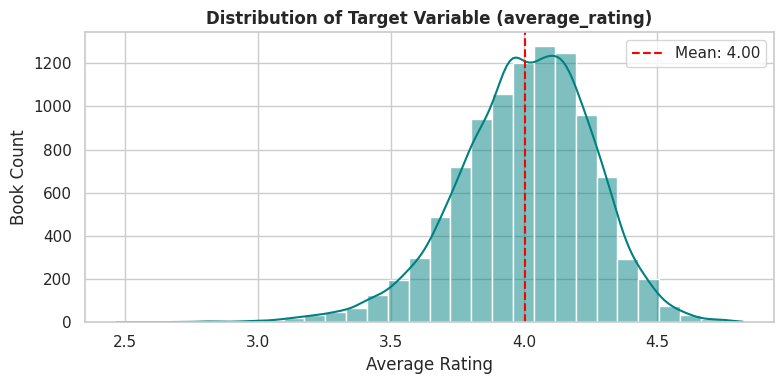

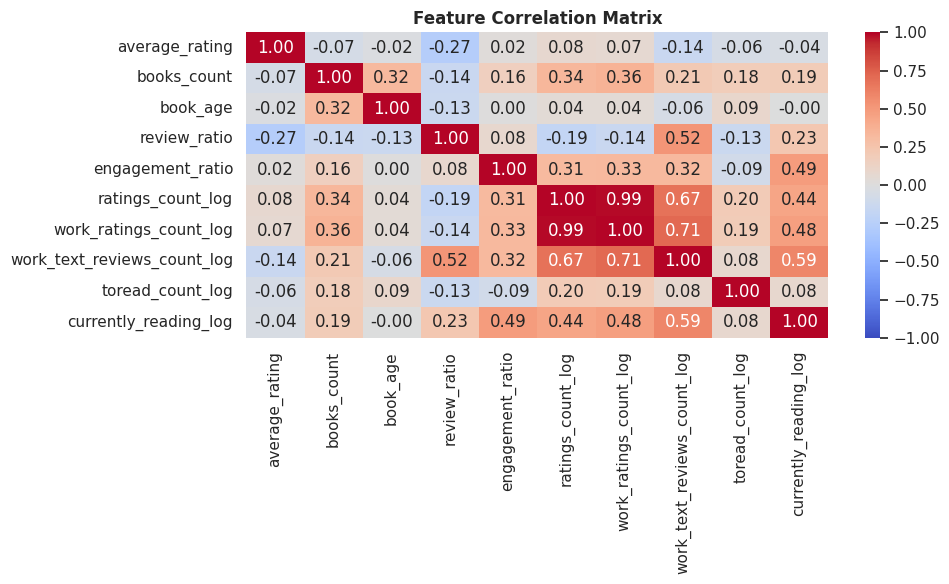

In [29]:
sns.set_theme(style="whitegrid")
plt.rcParams['figure.dpi'] = 100

# 1. Target Variable Distribution
plt.figure(figsize=(8, 4))
sns.histplot(data['average_rating'], bins=30, kde=True, color='teal')
plt.axvline(data['average_rating'].mean(), color='red', linestyle='--', label=f"Mean: {data['average_rating'].mean():.2f}")
plt.title("Distribution of Target Variable (average_rating)", fontweight='bold')
plt.xlabel("Average Rating")
plt.ylabel("Book Count")
plt.legend()
plt.tight_layout()
plt.show()

# 2. Correlation Matrix
plt.figure(figsize=(10, 6))
corr_cols = [
    'average_rating', 'books_count', 'book_age', 'review_ratio',
    'engagement_ratio', 'ratings_count_log', 'work_ratings_count_log',
    'work_text_reviews_count_log', 'toread_count_log', 'currently_reading_log'
]
sns.heatmap(data[corr_cols].corr(), annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1)
plt.title("Feature Correlation Matrix", fontweight='bold')
plt.tight_layout()
plt.show()

In [30]:
from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.preprocessing import RobustScaler, OneHotEncoder, TargetEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Feature Sets
target = 'average_rating'
numeric_features = [
    'books_count', 'book_age', 'review_ratio', 'engagement_ratio',
    'ratings_count_log', 'work_ratings_count_log',
    'work_text_reviews_count_log', 'toread_count_log', 'currently_reading_log'
]
categorical_low = ['language_code']
categorical_high = ['authors']

X = data[numeric_features + categorical_low + categorical_high + ['tag_name']]
y = data[target]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Column Preprocessor
svr_preprocessor = ColumnTransformer([
    ('num', RobustScaler(), numeric_features),
    ('cat_low', OneHotEncoder(handle_unknown='ignore'), categorical_low),
    ('cat_high', TargetEncoder(smooth="auto", cv=5), categorical_high),
    ('tags', Pipeline([
        ('tfidf', TfidfVectorizer(max_features=200, stop_words='english')),
        ('svd', TruncatedSVD(n_components=10, random_state=42))
    ]), 'tag_name')
])

X_train_svr = svr_preprocessor.fit_transform(X_train, y_train)
X_test_svr = svr_preprocessor.transform(X_test)

# Tuned SVR Fit
best_svr = SVR(kernel='rbf', C=2, epsilon=0.1, gamma=0.05)
best_svr.fit(X_train_svr, y_train)
svr_preds = best_svr.predict(X_test_svr)

print("="*50)
print("TUNED SVR TEST RESULTS")
print("="*50)
print(f"Test MAE:   {mean_absolute_error(y_test, svr_preds):.4f}")
print(f"Test RMSE:  {np.sqrt(mean_squared_error(y_test, svr_preds)):.4f}")
print(f"Test R2:    {r2_score(y_test, svr_preds):.4f}")
print("="*50)

TUNED SVR TEST RESULTS
Test MAE:   0.1363
Test RMSE:  0.1823
Test R2:    0.4574


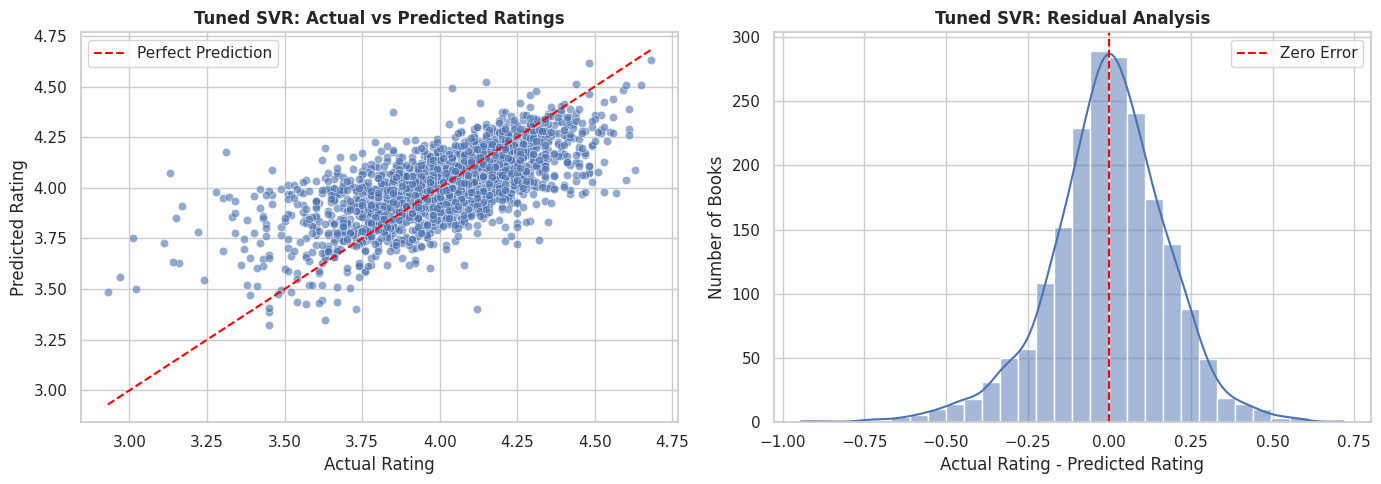

In [31]:
# -------------------------------------------------------------
# SVR: ACTUAL VS PREDICTED RATINGS & RESIDUAL ANALYSIS
# -------------------------------------------------------------

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# -------------------------------------------------------------
# PLOT 1: Actual vs Predicted Ratings
# -------------------------------------------------------------

sns.scatterplot(
    x=np.array(y_test),
    y=svr_preds,
    alpha=0.6,
    ax=axes[0]
)

# Perfect prediction reference line
axes[0].plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color='red',
    linestyle='--',
    label='Perfect Prediction'
)

axes[0].set_title(
    "Tuned SVR: Actual vs Predicted Ratings",
    fontweight='bold'
)
axes[0].set_xlabel("Actual Rating")
axes[0].set_ylabel("Predicted Rating")
axes[0].legend()

# -------------------------------------------------------------
# PLOT 2: Prediction Error Distribution
# -------------------------------------------------------------

residuals = np.array(y_test) - svr_preds

sns.histplot(
    residuals,
    bins=30,
    kde=True,
    ax=axes[1]
)

axes[1].axvline(
    0,
    color='red',
    linestyle='--',
    label='Zero Error'
)

axes[1].set_title(
    "Tuned SVR: Residual Analysis",
    fontweight='bold'
)
axes[1].set_xlabel("Actual Rating - Predicted Rating")
axes[1].set_ylabel("Number of Books")
axes[1].legend()

plt.tight_layout()
plt.show()

In [32]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer

rf_preprocessor = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), numeric_features),
    ("cat_low", OneHotEncoder(handle_unknown="ignore"), categorical_low),
    ("cat_high", TargetEncoder(smooth="auto", cv=5, random_state=42), categorical_high),
    ("tags", Pipeline([
        ("tfidf", TfidfVectorizer(max_features=200, stop_words="english")),
        ("svd", TruncatedSVD(n_components=10, random_state=42))
    ]), "tag_name")
])

rf_pipeline = Pipeline([
    ("preprocessor", rf_preprocessor),
    ("rf", RandomForestRegressor(
        n_estimators=200,
        max_depth=14,
        min_samples_leaf=4,
        min_samples_split=8,
        max_features=0.7,
        random_state=42,
        n_jobs=-1
    ))
])

rf_pipeline.fit(X_train, y_train)

rf_train_pred = rf_pipeline.predict(X_train)
rf_test_pred = rf_pipeline.predict(X_test)

rf_mae = mean_absolute_error(y_test, rf_test_pred)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_test_pred))
rf_train_r2 = r2_score(y_train, rf_train_pred)
rf_test_r2 = r2_score(y_test, rf_test_pred)

print("="*50)
print("REGULARIZED RANDOM FOREST EVALUATION METRICS")
print("="*50)
print(f"Test MAE:       {rf_mae:.4f}")
print(f"Test RMSE:      {rf_rmse:.4f}")
print(f"Training R2:    {rf_train_r2:.4f}")
print(f"Testing R2:     {rf_test_r2:.4f}")
print(f"Overfit Gap:    {rf_train_r2 - rf_test_r2:.4f}")
print("="*50)

REGULARIZED RANDOM FOREST EVALUATION METRICS
Test MAE:       0.1270
Test RMSE:      0.1700
Training R2:    0.8282
Testing R2:     0.5283
Overfit Gap:    0.2999


In [33]:
from sklearn.model_selection import KFold, cross_validate

rf_cv = KFold(n_splits=5, shuffle=True, random_state=42)
rf_cv_scores = cross_validate(
    rf_pipeline,
    X_train,
    y_train,
    cv=rf_cv,
    scoring={
        "r2": "r2",
        "rmse": "neg_root_mean_squared_error",
        "mae": "neg_mean_absolute_error"
    },
    return_train_score=True,
    n_jobs=-1
)

print("="*50)
print("RANDOM FOREST 5-FOLD CROSS-VALIDATION RESULTS")
print("="*50)
print(f"Training CV R2:     {np.mean(rf_cv_scores['train_r2']):.4f}")
print(f"Validation CV R2:   {np.mean(rf_cv_scores['test_r2']):.4f}")
print(f"Training CV RMSE:   {-np.mean(rf_cv_scores['train_rmse']):.4f}")
print(f"Validation CV RMSE: {-np.mean(rf_cv_scores['test_rmse']):.4f}")
print(f"Training CV MAE:    {-np.mean(rf_cv_scores['train_mae']):.4f}")
print(f"Validation CV MAE:  {-np.mean(rf_cv_scores['test_mae']):.4f}")
print("="*50)

RANDOM FOREST 5-FOLD CROSS-VALIDATION RESULTS
Training CV R2:     0.8271
Validation CV R2:   0.4824
Training CV RMSE:   0.1065
Validation CV RMSE: 0.1842
Training CV MAE:    0.0745
Validation CV MAE:  0.1378


In [34]:
import os
import json
import joblib

# Create standard models directory
models_dir = "models"
os.makedirs(models_dir, exist_ok=True)

# -------------------------------------------------------------
# 1. SAVE SVR MODEL & PREPROCESSOR
# -------------------------------------------------------------
joblib.dump(svr_preprocessor, os.path.join(models_dir, "svr_preprocessor.joblib"))
joblib.dump(best_svr, os.path.join(models_dir, "svr_model.joblib"))

svr_metrics_data = {
    "Model": "Hyperparameter Tuned SVR",
    "Parameters": {"kernel": "rbf", "C": 2, "epsilon": 0.1, "gamma": 0.05},
    "Test MAE": float(round(mean_absolute_error(y_test, svr_preds), 4)),
    "Test RMSE": float(round(np.sqrt(mean_squared_error(y_test, svr_preds)), 4)),
    "Test R2 Score": float(round(r2_score(y_test, svr_preds), 4))
}

with open(os.path.join(models_dir, "svr_metrics.json"), "w") as f:
    json.dump(svr_metrics_data, f, indent=4)

print("✓ Saved SVR artifacts (preprocessor, model, metrics)")

# -------------------------------------------------------------
# 2. SAVE RANDOM FOREST PIPELINE
# -------------------------------------------------------------
joblib.dump(rf_pipeline, os.path.join(models_dir, "rf_pipeline.joblib"))

rf_metrics_data = {
    "Model": "Regularized Random Forest",
    "Parameters": {"n_estimators": 200, "max_depth": 14, "min_samples_leaf": 4, "min_samples_split": 8},
    "Test MAE": float(round(rf_mae, 4)),
    "Test RMSE": float(round(rf_rmse, 4)),
    "Test R2 Score": float(round(rf_test_r2, 4)),
    "Training R2 Score": float(round(rf_train_r2, 4)),
    "Validation CV R2": float(round(np.mean(rf_cv_scores['test_r2']), 4))
}

with open(os.path.join(models_dir, "rf_metrics.json"), "w") as f:
    json.dump(rf_metrics_data, f, indent=4)

print("✓ Saved Random Forest artifacts (full pipeline, metrics)")


✓ Saved SVR artifacts (preprocessor, model, metrics)
✓ Saved Random Forest artifacts (full pipeline, metrics)


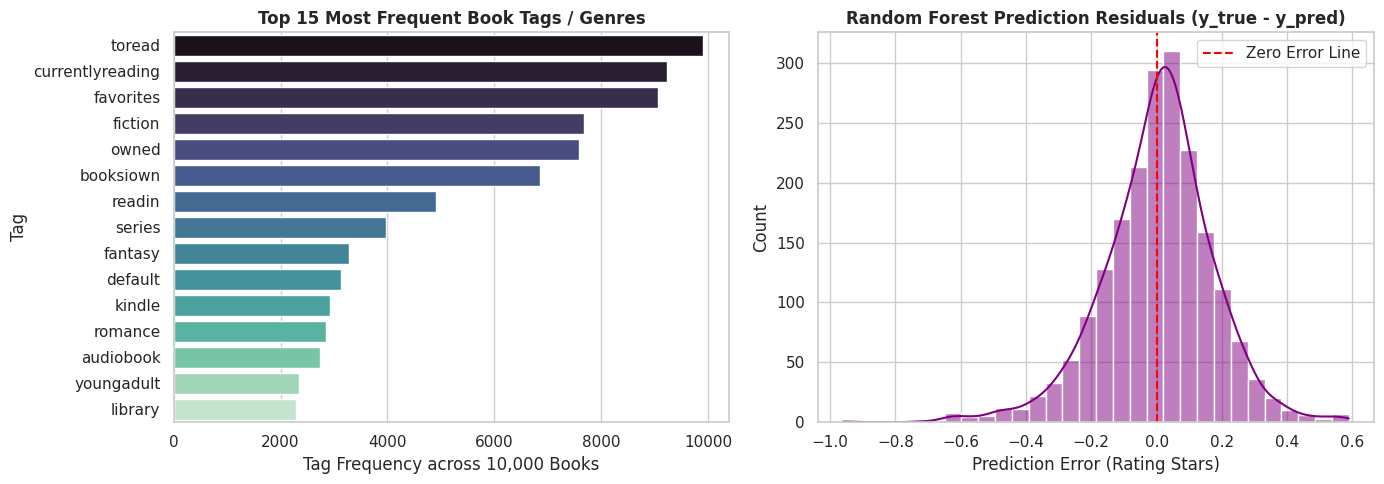

In [35]:
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# -------------------------------------------------------------
# PLOT 1: Top 15 Most Frequent Tags (Text Feature Justification)
# -------------------------------------------------------------
all_tags = [tag.strip() for text in data['tag_name'] for tag in text.split(',') if tag.strip()]
top_tags = pd.DataFrame(Counter(all_tags).most_common(15), columns=['Tag', 'Count'])

sns.barplot(data=top_tags, x='Count', y='Tag', palette='mako', ax=axes[0])
axes[0].set_title("Top 15 Most Frequent Book Tags / Genres", fontweight='bold')
axes[0].set_xlabel("Tag Frequency across 10,000 Books")

# -------------------------------------------------------------
# PLOT 2: Random Forest Residual Analysis (Error Distribution)
# -------------------------------------------------------------
residuals = y_test - rf_test_pred
sns.histplot(residuals, bins=30, kde=True, color='purple', ax=axes[1])
axes[1].axvline(0, color='red', linestyle='--', label='Zero Error Line')
axes[1].set_title("Random Forest Prediction Residuals (y_true - y_pred)", fontweight='bold')
axes[1].set_xlabel("Prediction Error (Rating Stars)")
axes[1].legend()

plt.tight_layout()
plt.show()

In [36]:
# -------------------------------------------------------------
# KNN REGRESSION: HYPERPARAMETER TUNING
# -------------------------------------------------------------

from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Create KNN pipeline using your existing preprocessing
knn_pipeline = Pipeline([
    ('preprocessor', svr_preprocessor),
    ('knn', KNeighborsRegressor())
])

# Test different KNN settings
param_grid = {
    'knn__n_neighbors': [3, 5, 7, 9, 11, 15, 21, 31],
    'knn__weights': ['uniform', 'distance'],
    'knn__p': [1, 2]
}

# Find the best parameters using 5-fold cross-validation
knn_grid = GridSearchCV(
    estimator=knn_pipeline,
    param_grid=param_grid,
    cv=5,
    scoring='neg_mean_absolute_error',
    n_jobs=-1,
    verbose=1
)

# Train and tune the model
knn_grid.fit(X_train, y_train)

# Best model and predictions
best_knn = knn_grid.best_estimator_
knn_test_pred = best_knn.predict(X_test)

# -------------------------------------------------------------
# EVALUATION
# -------------------------------------------------------------

knn_mae = mean_absolute_error(y_test, knn_test_pred)
knn_mse = mean_squared_error(y_test, knn_test_pred)
knn_rmse = np.sqrt(knn_mse)
knn_r2 = r2_score(y_test, knn_test_pred)

print("=" * 50)
print("TUNED KNN REGRESSION RESULTS")
print("=" * 50)

print("Best Parameters:", knn_grid.best_params_)
print(f"Best CV MAE: {-knn_grid.best_score_:.5f}")
print(f"Test MAE:    {knn_mae:.5f}")
print(f"Test MSE:    {knn_mse:.5f}")
print(f"Test RMSE:   {knn_rmse:.5f}")
print(f"Test R2:     {knn_r2:.5f}")

print("=" * 50)

Fitting 5 folds for each of 32 candidates, totalling 160 fits
TUNED KNN REGRESSION RESULTS
Best Parameters: {'knn__n_neighbors': 15, 'knn__p': 1, 'knn__weights': 'distance'}
Best CV MAE: 0.15958
Test MAE:    0.15198
Test MSE:    0.03949
Test RMSE:   0.19871
Test R2:     0.35551


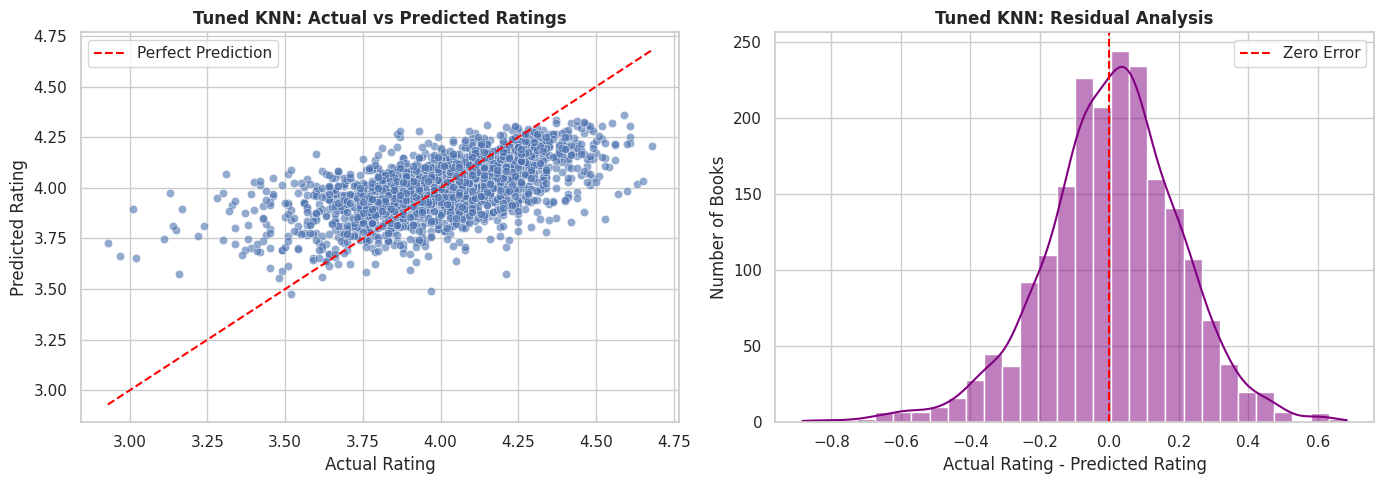

In [37]:

import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# -------------------------------------------------------------
# PLOT 1: Actual vs Predicted Ratings
# -------------------------------------------------------------
sns.scatterplot(
    x=np.array(y_test),
    y=knn_test_pred,
    alpha=0.6,
    ax=axes[0]
)

axes[0].plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color='red',
    linestyle='--',
    label='Perfect Prediction'
)

axes[0].set_title(
    "Tuned KNN: Actual vs Predicted Ratings",
    fontweight='bold'
)
axes[0].set_xlabel("Actual Rating")
axes[0].set_ylabel("Predicted Rating")
axes[0].legend()

# -------------------------------------------------------------
# PLOT 2: Prediction Error Distribution
# -------------------------------------------------------------
residuals = np.array(y_test) - knn_test_pred

sns.histplot(
    residuals,
    bins=30,
    kde=True,
    color='purple',
    ax=axes[1]
)

axes[1].axvline(
    0,
    color='red',
    linestyle='--',
    label='Zero Error'
)

axes[1].set_title(
    "Tuned KNN: Residual Analysis",
    fontweight='bold'
)
axes[1].set_xlabel("Actual Rating - Predicted Rating")
axes[1].set_ylabel("Number of Books")
axes[1].legend()

plt.tight_layout()
plt.show()


In [44]:
# -------------------------------------------------------------
# SAVE KNN MODEL, PREPROCESSOR & EVALUATION METRICS
# -------------------------------------------------------------

# Create models directory if it doesn't exist
models_dir = "models"
os.makedirs(models_dir, exist_ok=True)

# 1. Save the complete tuned KNN pipeline
# Includes preprocessing and the trained KNN model
joblib.dump(best_knn, os.path.join(models_dir, "knn_pipeline.joblib"))

# 2. Save the KNN preprocessor separately for reference
joblib.dump(
    best_knn.named_steps["preprocessor"],
    os.path.join(models_dir, "knn_preprocessor.joblib")
)

# 3. Save evaluation metrics
knn_metrics_data = {
    "Model": "Tuned KNN Regressor",
    "Parameters": {
        "n_neighbors": int(best_knn.named_steps["knn"].n_neighbors),
        "weights": best_knn.named_steps["knn"].weights,
        "p": int(best_knn.named_steps["knn"].p)
    },
    "Best CV MAE": float(round(-knn_grid.best_score_, 5)),
    "Test MAE": float(round(mean_absolute_error(y_test, knn_test_pred), 5)),
    "Test MSE": float(round(mean_squared_error(y_test, knn_test_pred), 5)),
    "Test RMSE": float(round(np.sqrt(mean_squared_error(y_test, knn_test_pred)), 5)),
    "Test R2 Score": float(round(r2_score(y_test, knn_test_pred), 5))
}

with open(os.path.join(models_dir, "knn_metrics.json"), "w") as f:
    json.dump(knn_metrics_data, f, indent=4)

print("KNN model files saved successfully!")
print("\nSaved files:")
print("1. models/knn_pipeline.joblib")
print("2. models/knn_preprocessor.joblib")
print("3. models/knn_metrics.json")

print("\nKNN Evaluation Metrics:")
print(json.dumps(knn_metrics_data, indent=4))

KNN model files saved successfully!

Saved files:
1. models/knn_pipeline.joblib
2. models/knn_preprocessor.joblib
3. models/knn_metrics.json

KNN Evaluation Metrics:
{
    "Model": "Tuned KNN Regressor",
    "Parameters": {
        "n_neighbors": 15,
        "weights": "distance",
        "p": 1
    },
    "Best CV MAE": 0.15958,
    "Test MAE": 0.15198,
    "Test MSE": 0.03949,
    "Test RMSE": 0.19871,
    "Test R2 Score": 0.35551
}


Linear Regression

In [38]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import cross_val_score, KFold
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# NOTE: this cell reuses X_train_svr, X_test_svr, y_train, y_test and best_svr
# created in the preprocessing/SVR cells above, so every model sees identical features.

def evaluate(name, model, Xtr, ytr, Xte, yte):
    model.fit(Xtr, ytr)
    tr_pred = model.predict(Xtr)
    te_pred = model.predict(Xte)
    return {
        "Model": name,
        "Train R2": r2_score(ytr, tr_pred),
        "Test MAE": mean_absolute_error(yte, te_pred),
        "Test MSE": mean_squared_error(yte, te_pred),
        "Test RMSE": np.sqrt(mean_squared_error(yte, te_pred)),
        "Test R2": r2_score(yte, te_pred),
    }, te_pred

# 1. Baselines: predict-the-mean, then Linear Regression
dummy_res, _ = evaluate("Mean Baseline", DummyRegressor(strategy="mean"),
                        X_train_svr, y_train, X_test_svr, y_test)

lin_reg = LinearRegression()
lin_res, lin_preds = evaluate("Linear Regression", lin_reg,
                              X_train_svr, y_train, X_test_svr, y_test)

# 2. Regularised variants for comparison
ridge_res, _ = evaluate("Ridge (alpha=1.0)", Ridge(alpha=1.0),
                        X_train_svr, y_train, X_test_svr, y_test)
# Lasso sometimes needs max_iter to converge
lasso_res, _ = evaluate("Lasso (alpha=0.001)", Lasso(alpha=0.001, max_iter=10000),
                        X_train_svr, y_train, X_test_svr, y_test)

# 3. SVR from the earlier cell (best_svr) for the final comparison
svr_preds = best_svr.predict(X_test_svr)
svr_res = {
    "Model": "SVR (tuned)",
    "Train R2": r2_score(y_train, best_svr.predict(X_train_svr)),
    "Test MAE": mean_absolute_error(y_test, svr_preds),
    "Test MSE": mean_squared_error(y_test, svr_preds),
    "Test RMSE": np.sqrt(mean_squared_error(y_test, svr_preds)),
    "Test R2": r2_score(y_test, svr_preds),
}

results = pd.DataFrame([dummy_res, lin_res, ridge_res, lasso_res, svr_res]).round(4)
print("=" * 60)
print("MODEL COMPARISON (same train/test split)")
print("=" * 60)
display(results)

# 4. 5-fold cross-validation for Linear Regression (more reliable than one split)
cv = KFold(n_splits=5, shuffle=True, random_state=42)
cv_rmse = -cross_val_score(LinearRegression(), X_train_svr, y_train,
                           scoring="neg_root_mean_squared_error", cv=cv)
cv_r2 = cross_val_score(LinearRegression(), X_train_svr, y_train, scoring="r2", cv=cv)
print(f"\nLinear Regression 5-fold CV RMSE: {cv_rmse.mean():.4f} (+/- {cv_rmse.std():.4f})")
print(f"Linear Regression 5-fold CV R2:   {cv_r2.mean():.4f} (+/- {cv_r2.std():.4f})")

MODEL COMPARISON (same train/test split)


,Model,Train R2,Test MAE,Test MSE,Test RMSE,Test R2
0,Mean Baseline,0.0000,0.1966,0.0613,0.2476,-0.0009
1,Linear Regression,0.3893,0.1436,0.0352,0.1877,0.4248
2,Ridge (alpha=1.0),0.3891,0.1436,0.0352,0.1877,0.4249
3,Lasso (alpha=0.001),0.3789,0.1440,0.0355,0.1883,0.4212
4,SVR (tuned),0.5390,0.1363,0.0332,0.1823,0.4574



Linear Regression 5-fold CV RMSE: 0.2015 (+/- 0.0037)
Linear Regression 5-fold CV R2:   0.3801 (+/- 0.0151)


Intercept: 1.3869


,Feature,Coefficient
32,cat_high__authors,0.697062
33,tags__truncatedsvd0,-0.397029
22,cat_low__language_code_mul,0.357634
16,cat_low__language_code_fil,0.278878
23,cat_low__language_code_nor,-0.216397
5,num__work_ratings_count_log,0.183887
30,cat_low__language_code_swe,-0.156922
35,tags__truncatedsvd2,0.115653
4,num__ratings_count_log,-0.115624
38,tags__truncatedsvd5,0.112329


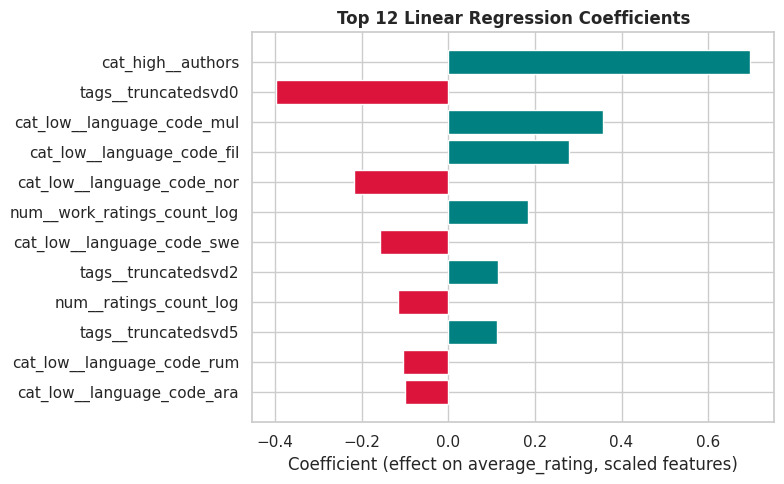

In [40]:
# Coefficients: which features drive the predicted rating?
feature_names = svr_preprocessor.get_feature_names_out()
coef_df = pd.DataFrame({"Feature": feature_names, "Coefficient": lin_reg.coef_})
coef_df["Abs"] = coef_df["Coefficient"].abs()
coef_df = coef_df.sort_values("Abs", ascending=False).drop(columns="Abs")
print("Intercept:", round(lin_reg.intercept_, 4))
display(coef_df.head(15))

plt.figure(figsize=(8, 5))
top = coef_df.head(12).iloc[::-1]
plt.barh(top["Feature"], top["Coefficient"],
         color=["teal" if c > 0 else "crimson" for c in top["Coefficient"]])
plt.title("Top 12 Linear Regression Coefficients", fontweight="bold")
plt.xlabel("Coefficient (effect on average_rating, scaled features)")
plt.tight_layout()
plt.show()

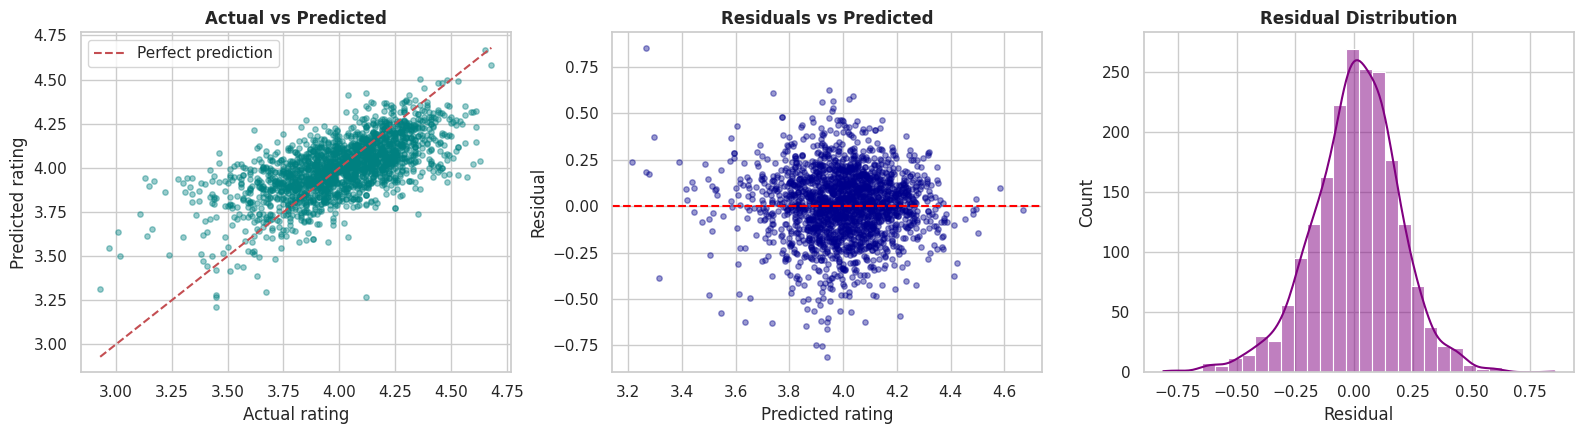

In [41]:
# Diagnostics: predictions vs actual, and residuals
residuals = y_test - lin_preds

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

axes[0].scatter(y_test, lin_preds, alpha=0.4, color="teal", s=15)
lims = [min(y_test.min(), lin_preds.min()), max(y_test.max(), lin_preds.max())]
axes[0].plot(lims, lims, "r--", label="Perfect prediction")
axes[0].set_title("Actual vs Predicted", fontweight="bold")
axes[0].set_xlabel("Actual rating"); axes[0].set_ylabel("Predicted rating")
axes[0].legend()

axes[1].scatter(lin_preds, residuals, alpha=0.4, color="darkblue", s=15)
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set_title("Residuals vs Predicted", fontweight="bold")
axes[1].set_xlabel("Predicted rating"); axes[1].set_ylabel("Residual")

sns.histplot(residuals, bins=30, kde=True, ax=axes[2], color="purple")
axes[2].set_title("Residual Distribution", fontweight="bold")
axes[2].set_xlabel("Residual")

plt.tight_layout()
plt.show()

In [49]:
# Save the linear regression artifacts, same pattern as the SVR cells
import os
lr_dir = "models"
os.makedirs(lr_dir, exist_ok=True)
# joblib.dump(preprocessor, os.path.join(lr_dir, "lr_preprocessor.joblib"))
joblib.dump(lin_reg, os.path.join(lr_dir, "lr_model.joblib"))

with open(os.path.join(lr_dir, "lr_metrics.json"), "w") as f:
    json.dump({
        "Model": "Linear Regression",
        "Test MAE": float(round(lin_res["Test MAE"], 4)),
        "Test MSE": float(round(lin_res["Test MSE"], 4)),
        "Test RMSE": float(round(lin_res["Test RMSE"], 4)),
        "Test R2 Score": float(round(lin_res["Test R2"], 4)),
        "CV RMSE": float(round(cv_rmse.mean(), 4)),
        "CV R2": float(round(cv_r2.mean(), 4)),
    }, f, indent=4)
print("--> Saved to", lr_dir)

--> Saved to models


In [48]:
# ============================================================
# FINAL MODEL COMPARISON
# ============================================================

import pandas as pd
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from IPython.display import display

models_predictions = {
    "Mean Baseline": dummy_res and DummyRegressor(strategy="mean").fit(X_train_svr, y_train).predict(X_test_svr),
    "Linear Regression": lin_preds,
    "Ridge Regression": Ridge(alpha=1.0).fit(X_train_svr, y_train).predict(X_test_svr),
    "Lasso Regression": Lasso(alpha=0.001, max_iter=10000).fit(X_train_svr, y_train).predict(X_test_svr),
    "SVR": svr_preds,
    "Random Forest": rf_test_pred,
    "KNN": knn_test_pred
}

comparison = []

for name, predictions in models_predictions.items():
    comparison.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, predictions),
        "MSE": mean_squared_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "R2": r2_score(y_test, predictions)
    })

final_comparison = pd.DataFrame(comparison)
final_comparison = final_comparison.sort_values("RMSE").reset_index(drop=True)

display(final_comparison.round(4))

,Model,MAE,MSE,RMSE,R2
0,Random Forest,0.1270,0.0289,0.1700,0.5283
1,SVR,0.1363,0.0332,0.1823,0.4574
2,Ridge Regression,0.1436,0.0352,0.1877,0.4249
3,Linear Regression,0.1436,0.0352,0.1877,0.4248
4,Lasso Regression,0.1440,0.0355,0.1883,0.4212
5,KNN,0.1520,0.0395,0.1987,0.3555
6,Mean Baseline,0.1966,0.0613,0.2476,-0.0009
